# Автоматическая генерация и отбор признаков для RecSys

Проверяем, можно ли автоматически собрать компактный набор временных признаков, который конкурирует с ручным feature engineering.

Сравниваются **AutoFE**, ручной **baseline v1** и **все доступные кандидаты**. Данные — 3000 train- и 3000 dev-выдач MINDsmall. Основная метрика — **nDCG@10**.

**Как читать:** по умолчанию все дорогие вычисления выключены. Выполнение ноутбука сверху вниз загружает готовые результаты, показывает таблицы и строит график. Для воспроизведения отдельных экспериментов включите нужные флаги ниже.


In [1]:
import importlib
from dataclasses import asdict

import matplotlib.pyplot as plt
from IPython.display import display

# Обновляем модули после правок исходников, не перезапуская ядро.
for module_name in (
    'src.config', 'src.ranking_metrics', 'src.manual_feature_selection',
    'src.cv', 'src.evaluation', 'src.bandit_features', 'src.experiment_utils',
):
    importlib.reload(importlib.import_module(module_name))

from src.config import CatBoostClassifier, Path, json, np, pd, perf_counter
from src.bandit_features import FeatureArm, generate_arms, search_features, train_model
from src.evaluation import evaluate_quality
from src.experiment_utils import evaluate_ndcg, load_candidate_pool, prepare_experiment_data
from src.manual_feature_selection import make_catboost_matrix


## 1. Настройки и данные

Пути и параметры собраны в одном месте. Флаги включают вычисления; при `False` используются сохранённые результаты выбранного запуска.

In [2]:
DATA_DIR = Path('data')
RUN_DIR = Path('artifacts/auto_features_controlled_4seeds_1000')
BASELINE_PATH = Path('artifacts/manual_model_v1.cbm')

# По умолчанию — просмотр без обучения.
RUN_SEARCH = False
RUN_DEV = False
RUN_RANDOM = False
RUN_SEEDS = False

MODEL_PARAMS = {'iterations': 300, 'depth': 8, 'learning_rate': 0.05, 'thread_count': 4}
SEARCH_SETTINGS = {
    'budget': 1000,
    'max_features': 15,
    'min_gain': 0.001,
    'control_fraction': 0.2,
    'screen_iterations': 50,
    'n_finalists': 3,
    'seeds': (42, 0, 1, 2),
    'patience': 2,
}
RANDOM_SIZES = [3, 5, 8, 12, 24, 40]  # Полный набор добавляется автоматически.
RANDOM_REPEATS = 5
FINAL_SEEDS = [11, 22, 33, 44, 55]

train_data = pd.read_csv(DATA_DIR / 'train_v1.csv', parse_dates=['timestamp'])
dev_data = pd.read_csv(DATA_DIR / 'dev_v1.csv', parse_dates=['timestamp'])
assert train_data.timestamp.max() < dev_data.timestamp.min()

data_info = pd.DataFrame([
    {
        'Выборка': name, 'Выдач': data.impression_id.nunique(),
        'Строк': len(data), 'Доля кликов': data.label.mean(),
        'Начало': data.timestamp.min(), 'Конец': data.timestamp.max(),
    }
    for name, data in [('Train', train_data), ('Dev', dev_data)]
]).set_index('Выборка')
display(data_info.round({'Доля кликов': 4}))


,Выдач,Строк,Доля кликов,Начало,Конец
Выборка,,,,,
Train,3000,114257,0.0397,2019-11-09 00:11:02,2019-11-14 23:55:04
Dev,3000,110621,0.0411,2019-11-15 00:06:08,2019-11-15 23:58:03


## 2. Автоматический отбор

Начальный вход — только `category` и `subcategory`. Остальные признаки становятся руками-кандидатами: группировка × статистика × окно, а также признаки истории MIND и длины текстов.

Ранние **80% train** используются для поиска, поздние **20%** — для выбора лучшего шага. После дешёвого скрининга на 50 деревьях три финалиста проверяются на 300 деревьях, трёх временных фолдах и четырёх seed. Награда — парный прирост nDCG@10. Константы и дубликаты исключаются. При двух шагах без улучшения контроля возвращается лучший набор.

Контроль участвует в выборе шага и **не является независимым тестом**. Все временные агрегаты используют только события строго раньше текущего timestamp.


In [3]:
if RUN_SEARCH:
    arms = generate_arms()
    result = search_features(
        data=train_data, arms=arms, model_params=MODEL_PARAMS, **SEARCH_SETTINGS,
    )

    RUN_DIR.mkdir(parents=True, exist_ok=True)
    result.model.save_model(str(RUN_DIR / 'model.cbm'))
    result.history.to_csv(RUN_DIR / 'search_history.csv', index=False)
    result.discarded_arms.to_csv(RUN_DIR / 'discarded_arms.csv', index=False)
    result.checkpoints.to_json(
        RUN_DIR / 'checkpoints.json', orient='records', force_ascii=False, indent=2,
    )
    run_summary = {
        'experiment': 'from_scratch_with_control',
        'base_features': ['category', 'subcategory'],
        'train_rows': len(train_data),
        'train_impressions': int(train_data.impression_id.nunique()),
        'candidate_arms': [asdict(arm) for arm in arms],
        'selected_arms': [asdict(arm) for arm in result.selected_arms],
        'feature_columns': result.feature_columns,
        'cv_score': result.cv_score,
        'control_score': result.control_score,
        'evaluations': result.evaluations,
        'trees_built': result.trees_built,
        'elapsed_seconds': result.elapsed_seconds,
        'search_settings': SEARCH_SETTINGS,
        'model_params': result.model.get_params(),
    }
    (RUN_DIR / 'summary.json').write_text(
        json.dumps(run_summary, ensure_ascii=False, indent=2), encoding='utf-8',
    )
else:
    print('Отбор не запускается: загружаем сохранённый результат.')

assert (RUN_DIR / 'summary.json').exists(), 'Нет результата: включите RUN_SEARCH или выберите RUN_DIR.'
summary = json.loads((RUN_DIR / 'summary.json').read_text(encoding='utf-8'))
checkpoints = pd.read_json(RUN_DIR / 'checkpoints.json')
selected_arms = [FeatureArm(**recipe) for recipe in summary['selected_arms']]
candidate_pool = load_candidate_pool(RUN_DIR)

baseline_model = CatBoostClassifier()
baseline_model.load_model(str(BASELINE_PATH))
feature_sets = {
    'auto': summary['feature_columns'],
    'v1': baseline_model.feature_names_,
    'all': summary['base_features'] + [arm.name for arm in candidate_pool],
}


Отбор не запускается: загружаем сохранённый результат.


In [4]:
print('Выбранные признаки:')
display(pd.DataFrame({'Признак': summary['feature_columns']}))

search_report = pd.DataFrame([{
    'Кандидатов до фильтрации': len(summary['candidate_arms']),
    'После фильтрации': len(candidate_pool),
    'Выбрано признаков': len(summary['feature_columns']),
    'Поисковый CV nDCG@10': summary['cv_score'],
    'Контрольный nDCG@10': summary['control_score'],
    'Обучений': summary['evaluations'],
    'Деревьев без финального fit': summary['trees_built'],
    'Время, мин': summary['elapsed_seconds'] / 60,
}])
display(search_report.round({
    'Поисковый CV nDCG@10': 6,
    'Контрольный nDCG@10': 6,
    'Время, мин': 1,
}))

print('Путь поиска: selected отмечает набор, выбранный по контролю.')
display(
    checkpoints[['step', 'added_arm', 'search_score', 'control_score', 'selected']]
    .round({'search_score': 6, 'control_score': 6})
)


Выбранные признаки:
Путь поиска: selected отмечает набор, выбранный по контролю.


,Признак
0,category
1,subcategory
2,history_subcategory_share
3,item_previous_ctr_3d
4,history_category_share


,Кандидатов до фильтрации,После фильтрации,Выбрано признаков,Поисковый CV nDCG@10,Контрольный nDCG@10,Обучений,Деревьев без финального fit,"Время, мин"
0,85,68,5,0.402415,0.334213,533,76150,20.6


,step,added_arm,search_score,control_score,selected
0,0,NaN,0.319359,0.262464,False
1,1,history_subcategory_share,0.359287,0.318751,False
2,2,item_previous_ctr_3d,0.398411,0.327557,False
3,3,history_category_share,0.402415,0.334213,True
4,4,history_category_clicks,0.404314,0.334552,False
5,5,history_unique_categories,0.406014,0.334200,False


## 3. Сравнение с ручным baseline на dev

Сравниваем готовые модели на одних и тех же 3000 dev-выдачах. Признаки рассчитываются в **rolling-протоколе**: доступны train и более ранние dev-события, текущий timestamp исключён. Модель на dev не обучается.

Для ROC-AUC, PR-AUC (average precision), MRR и nDCG больше — лучше; для LogLoss — меньше.


In [5]:
if RUN_DEV:
    _, selected_dev = prepare_experiment_data(train_data, dev_data, selected_arms)
    auto_model = CatBoostClassifier()
    auto_model.load_model(str(RUN_DIR / 'model.cbm'))
    assert auto_model.feature_names_ == summary['feature_columns']
    dev_results = {}

    for name, model in [('v1', baseline_model), ('auto', auto_model)]:
        print(f'{name}: {len(model.feature_names_)} признаков')
        matrix = make_catboost_matrix(selected_dev, model.feature_names_)
        dev_results[name] = evaluate_quality(
            valid=selected_dev,
            click_probability=model.predict_proba(matrix)[:, 1],
            train_click_rate=float(train_data.label.mean()),
        )

    dev_table = pd.DataFrame(dev_results).loc[
        ['roc_auc', 'pr_auc', 'mrr', 'ndcg@5', 'ndcg@10', 'logloss']
    ]
    dev_table['auto_minus_v1'] = dev_table['auto'] - dev_table['v1']
    dev_table.to_csv(RUN_DIR / 'dev_comparison.csv')
    (RUN_DIR / 'dev_metrics.json').write_text(
        json.dumps(dev_results, ensure_ascii=False, indent=2), encoding='utf-8',
    )

dev_table = pd.read_csv(RUN_DIR / 'dev_comparison.csv', index_col=0)
dev_metrics = json.loads((RUN_DIR / 'dev_metrics.json').read_text(encoding='utf-8'))
display(dev_table.round(6))


,v1,auto,auto_minus_v1
roc_auc,0.722480,0.729720,0.007240
pr_auc,0.111639,0.114005,0.002366
mrr,0.380928,0.387468,0.006539
ndcg@5,0.362918,0.369762,0.006845
ndcg@10,0.426394,0.431368,0.004974
logloss,0.159041,0.158064,-0.000977


## 4. Случайные наборы признаков

Проверяем пользу отбора: сравниваем AutoFE со случайными наборами из **той же отфильтрованной библиотеки, включая все временные окна**.

Две категории всегда включены и входят в общее число признаков n. Для каждого промежуточного n берём пять случайных наборов; для полного набора достаточно одного. Seed CatBoost фиксирован: разброс отражает состав признаков. На графике полоса означает **±1 std**, а не доверительный интервал.

Полная подготовка признаков выполняется только при запуске новых обучений и затем используется также проверкой пяти seed.


In [6]:
if RUN_RANDOM or RUN_SEEDS:
    pool_train, pool_dev = prepare_experiment_data(train_data, dev_data, candidate_pool)

full_size = len(feature_sets['all'])
random_sizes = sorted({
    n for n in [*RANDOM_SIZES, full_size]
    if len(summary['base_features']) <= n <= full_size
})
random_dir = RUN_DIR / 'random_subsets'
seed_dir = RUN_DIR / 'final_seed_comparison'


In [7]:
if RUN_RANDOM:
    rng = np.random.default_rng(2026)
    params = {**summary['model_params'], 'random_seed': 42}
    random_rows = []
    total = sum(1 if n == full_size else RANDOM_REPEATS for n in random_sizes)
    random_dir.mkdir(parents=True, exist_ok=True)
    started = perf_counter()

    for n in random_sizes:
        repeats = 1 if n == full_size else RANDOM_REPEATS
        for repeat in range(1, repeats + 1):
            positions = np.sort(rng.choice(
                len(candidate_pool), size=n - len(summary['base_features']), replace=False,
            )) if n != full_size else np.arange(len(candidate_pool))
            features = summary['base_features'] + [candidate_pool[i].name for i in positions]
            model = train_model(pool_train, features, params)
            score = evaluate_ndcg(model, pool_dev)
            random_rows.append({
                'n_features': n, 'repeat': repeat, 'ndcg@10': score,
                'features': json.dumps(features, ensure_ascii=False),
            })
            pd.DataFrame(random_rows).to_csv(random_dir / 'scores.csv', index=False)
            done = len(random_rows)
            eta = (perf_counter() - started) / done * (total - done)
            print(f'{done}/{total}: n={n}, nDCG@10={score:.6f}, осталось ~{eta / 60:.1f} мин')
else:
    print('Случайные наборы: используем сохранённые оценки.')


Случайные наборы: используем сохранённые оценки.


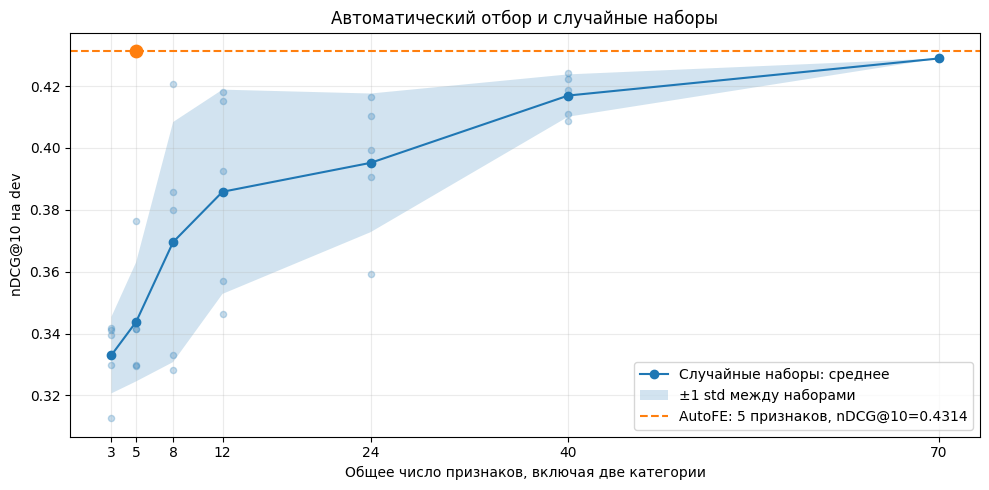

,n_features,mean,std,repeats
0,3,0.333004,0.012364,5
1,5,0.343751,0.019244,5
2,8,0.369575,0.038804,5
3,12,0.385830,0.033025,5
4,24,0.395189,0.022409,5
5,40,0.416945,0.006840,5
6,70,0.428928,0.000000,1


In [8]:
random_scores = pd.read_csv(random_dir / 'scores.csv')
random_curve = (
    random_scores.groupby('n_features')['ndcg@10']
    .agg(mean='mean', std='std', repeats='count')
    .reset_index()
)
random_curve['std'] = random_curve['std'].fillna(0)
auto_score = dev_metrics['auto']['ndcg@10']
auto_size = len(summary['feature_columns'])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(random_curve.n_features, random_curve['mean'], marker='o', label='Случайные наборы: среднее')
ax.fill_between(
    random_curve.n_features,
    random_curve['mean'] - random_curve['std'],
    random_curve['mean'] + random_curve['std'],
    alpha=0.2, label='±1 std между наборами',
)
ax.scatter(random_scores.n_features, random_scores['ndcg@10'], color='tab:blue', alpha=0.25, s=20)
ax.axhline(
    auto_score, color='tab:orange', linestyle='--',
    label=f'AutoFE: {auto_size} признаков, nDCG@10={auto_score:.4f}',
)
ax.scatter([auto_size], [auto_score], color='tab:orange', s=80, zorder=5)
ax.set(
    xlabel='Общее число признаков, включая две категории',
    ylabel='nDCG@10 на dev',
    title='Автоматический отбор и случайные наборы',
    xticks=random_curve.n_features,
)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
if RUN_RANDOM:
    random_curve.to_csv(random_dir / 'curve.csv', index=False)
    fig.savefig(random_dir / 'ndcg_vs_features.png', dpi=160)
    fig.savefig(random_dir / 'ndcg_vs_features.svg')
plt.show()
display(random_curve.round({'mean': 6, 'std': 6}))


## 5. Проверка на пяти новых seed

Фиксируем три набора: **AutoFE (5 признаков)**, **ручной v1 (24)** и **все кандидаты (70)**. Используем seed **11, 22, 33, 44, 55**, которые не участвовали в поиске.

Всего 15 обучений на всём train с одинаковыми параметрами. Для каждого seed считаем парную разницу AutoFE с двумя альтернативами. Отбор заново не проводится.


In [9]:
if RUN_SEEDS:
    assert not set(FINAL_SEEDS).intersection(summary['search_settings']['seeds'])
    seed_rows = []
    total = len(FINAL_SEEDS) * len(feature_sets)
    seed_dir.mkdir(parents=True, exist_ok=True)
    (seed_dir / 'settings.json').write_text(
        json.dumps({
            'seeds': FINAL_SEEDS, 'feature_sets': feature_sets,
            'model_params': summary['model_params'], 'metric': 'ndcg@10',
        }, ensure_ascii=False, indent=2), encoding='utf-8',
    )
    started = perf_counter()

    for seed in FINAL_SEEDS:
        params = {**summary['model_params'], 'random_seed': seed}
        for name, features in feature_sets.items():
            fit_started = perf_counter()
            model = train_model(pool_train, features, params)
            score = evaluate_ndcg(model, pool_dev)
            seed_rows.append({
                'seed': seed, 'model': name, 'n_features': len(features),
                'ndcg@10': score, 'seconds': perf_counter() - fit_started,
            })
            pd.DataFrame(seed_rows).to_csv(seed_dir / 'scores.csv', index=False)
            done = len(seed_rows)
            eta = (perf_counter() - started) / done * (total - done)
            print(f'{done}/{total}: seed={seed}, {name}, nDCG@10={score:.6f}, осталось ~{eta / 60:.1f} мин')
else:
    print('Пять seed: используем сохранённые оценки.')


Пять seed: используем сохранённые оценки.


In [10]:
seed_scores = pd.read_csv(seed_dir / 'scores.csv')
seed_summary = (
    seed_scores.groupby('model')['ndcg@10']
    .agg(mean='mean', std='std', min='min', max='max')
    .reindex(['auto', 'v1', 'all'])
)
seed_pairs = seed_scores.pivot(index='seed', columns='model', values='ndcg@10')
seed_pairs['auto_minus_v1'] = seed_pairs['auto'] - seed_pairs['v1']
seed_pairs['auto_minus_all'] = seed_pairs['auto'] - seed_pairs['all']
deltas = seed_pairs[['auto_minus_v1', 'auto_minus_all']]
delta_summary = deltas.agg(['mean', 'std', 'min', 'max']).T
delta_summary['wins'] = (deltas > 0).sum()
delta_summary['total'] = len(seed_pairs)

print('Среднее качество и разброс:')
display(seed_summary.round(6))
print('Парные оценки при одинаковом seed:')
display(seed_pairs.round(6))
print('Преимущество AutoFE и количество выигрышей:')
display(delta_summary.round({'mean': 6, 'std': 6, 'min': 6, 'max': 6}))
if RUN_SEEDS:
    seed_summary.to_csv(seed_dir / 'summary.csv')
    seed_pairs.to_csv(seed_dir / 'paired_scores.csv')
    delta_summary.to_csv(seed_dir / 'paired_deltas.csv')


Среднее качество и разброс:
Парные оценки при одинаковом seed:
Преимущество AutoFE и количество выигрышей:


,mean,std,min,max
model,,,,
auto,0.429856,0.001463,0.427558,0.431364
v1,0.424441,0.003485,0.419853,0.429443
all,0.425761,0.002118,0.423361,0.428145


model,all,auto,v1,auto_minus_v1,auto_minus_all
seed,,,,,
11,0.427839,0.427558,0.419853,0.007705,-0.000280
22,0.423361,0.430370,0.423501,0.006869,0.007009
33,0.424891,0.431364,0.425562,0.005801,0.006473
44,0.424568,0.429401,0.423843,0.005557,0.004832
55,0.428145,0.430588,0.429443,0.001144,0.002442


,mean,std,min,max,wins,total
model,,,,,,
auto_minus_v1,0.005416,0.002538,0.001144,0.007705,5,5
auto_minus_all,0.004095,0.003023,-0.000280,0.007009,4,5


## Что показывают эксперименты

- Сравнение на dev оценивает выбранный компактный набор относительно ручного baseline.
- График показывает пользу состава набора и сравнение со всеми кандидатами.
- Пять новых seed проверяют устойчивость выигрыша к случайности обучения.

Это минимальное исследование на фиксированной небольшой выборке. Dev многократно просматривался в ходе работы; результат нельзя считать оценкой на полностью нетронутом тесте. Проверка seed не заменяет проверку на другом временном периоде, а график случайных наборов не сравнивает вычислительные бюджеты методов.

Проверки реализации остаются в `tests/test_bandit_features.py`:
`python -m unittest discover -s tests -p 'test_bandit_features.py'`.
